In [1]:
%% MIT 18.03 Lecture 25: Convolution & Superposition of Impulse Responses
% Description: Simulates LTI systems via convolution and Control System Toolbox:
%              1) Phosphate Lake Model: x' + a*x = 1 + cos(b*t), x(0) = 0.
%              2) Impulse response kernel w(t) extracted via 'impulse'.
%              3) Equivalence check: Numerical Riemann Convolution vs. 'lsim' vs. Closed-form analytic.
%              4) Cascaded system associativity: (G1 * G2) * u = G1 * (G2 * u).
%
% % Required Toolboxes:
% %   - Control System Toolbox (tf, impulse, lsim, series).
%
% % MBD Concept Mapping: Demonstrates non-parametric LTI kernel identification w(t) = L^-1{G(s)},
% %                      the Duhamel convolution integral x(t) = \int_0^t w(t-tau)*q(tau) dtau,
% %                      and cascaded transfer function operator algebra.


clear; clc; close all;


%% =========================================================================
%% Part 1: Lake Phosphate Model Dynamic Convolution (Lecture Section [3])
%% =========================================================================
% Model: x' + a*x = q(t), where q(t) = 1 + cos(b*t) for t >= 0
a_decay = 1.0;  % Decay/carry-out rate
b_freq  = 2.0;  % Seasonal oscillation frequency (rad/s)
t_horizon = 8.0;


% Construct LTI Plant via Control System Toolbox: G(s) = 1 / (s + a)
G_lake = tf(1.0, [1.0, a_decay]);


% Time grid definition
dt = 0.005; % Fine step size for Riemann sum emulation
t_vec = 0:dt:t_horizon;


% Continuous input signal q(t)
q_input = 1.0 + cos(b_freq * t_vec);


% Method 1: Impulse response kernel extraction via Control System Toolbox
[w_kernel, ~] = impulse(G_lake, t_vec); % Analytic: w(t) = exp(-a*t)


% Numerical Convolution via Riemann Sum (Emulating Lecture Section [3])
% x(t) = sum_{k} w(t - k*dt) * q(k*dt) * dt
x_conv_full = conv(q_input, w_kernel) * dt;
x_conv_numeric = x_conv_full(1:length(t_vec)); % Truncate to evaluation horizon


% Method 2: Direct LTI simulation via Control System Toolbox 'lsim'
[x_lsim, ~] = lsim(G_lake, q_input, t_vec);


% Method 3: Closed-form Analytical Integration
% x(t) = (1/a)*(1 - e^{-at}) + [a*cos(bt) + b*sin(bt) - a*e^{-at}] / (a^2 + b^2)
term_dc = (1.0 / a_decay) * (1.0 - exp(-a_decay * t_vec));
term_ac = (a_decay * cos(b_freq * t_vec) + b_freq * sin(b_freq * t_vec) - ...
           a_decay * exp(-a_decay * t_vec)) / (a_decay^2 + b_freq^2);
x_analytic = term_dc + term_ac;


% Assess Numerical Agreement
err_conv_vs_lsim = max(abs(x_conv_numeric(:) - x_lsim(:)));
err_conv_vs_ana  = max(abs(x_conv_numeric(:) - x_analytic(:)));


fprintf('=== MIT 18.03 Lecture 25 Convolution Diagnostics ===\n');

=== MIT 18.03 Lecture 25 Convolution Diagnostics ===

In [2]:
fprintf('Decay Constant (a)          : %.2f\n', a_decay);

Decay Constant (a)          : 1.00

In [3]:
fprintf('Excitation Frequency (b)    : %.2f rad/s\n', b_freq);

Excitation Frequency (b)    : 2.00 rad/s

In [4]:
fprintf('Max Error (Convolution vs lsim)     : %e\n', err_conv_vs_lsim);

Max Error (Convolution vs lsim)     : 1.000000e-02

In [5]:
fprintf('Max Error (Convolution vs Analytic) : %e\n', err_conv_vs_ana);

Max Error (Convolution vs Analytic) : 1.000000e-02

In [6]:
fprintf('====================================================\n\n');


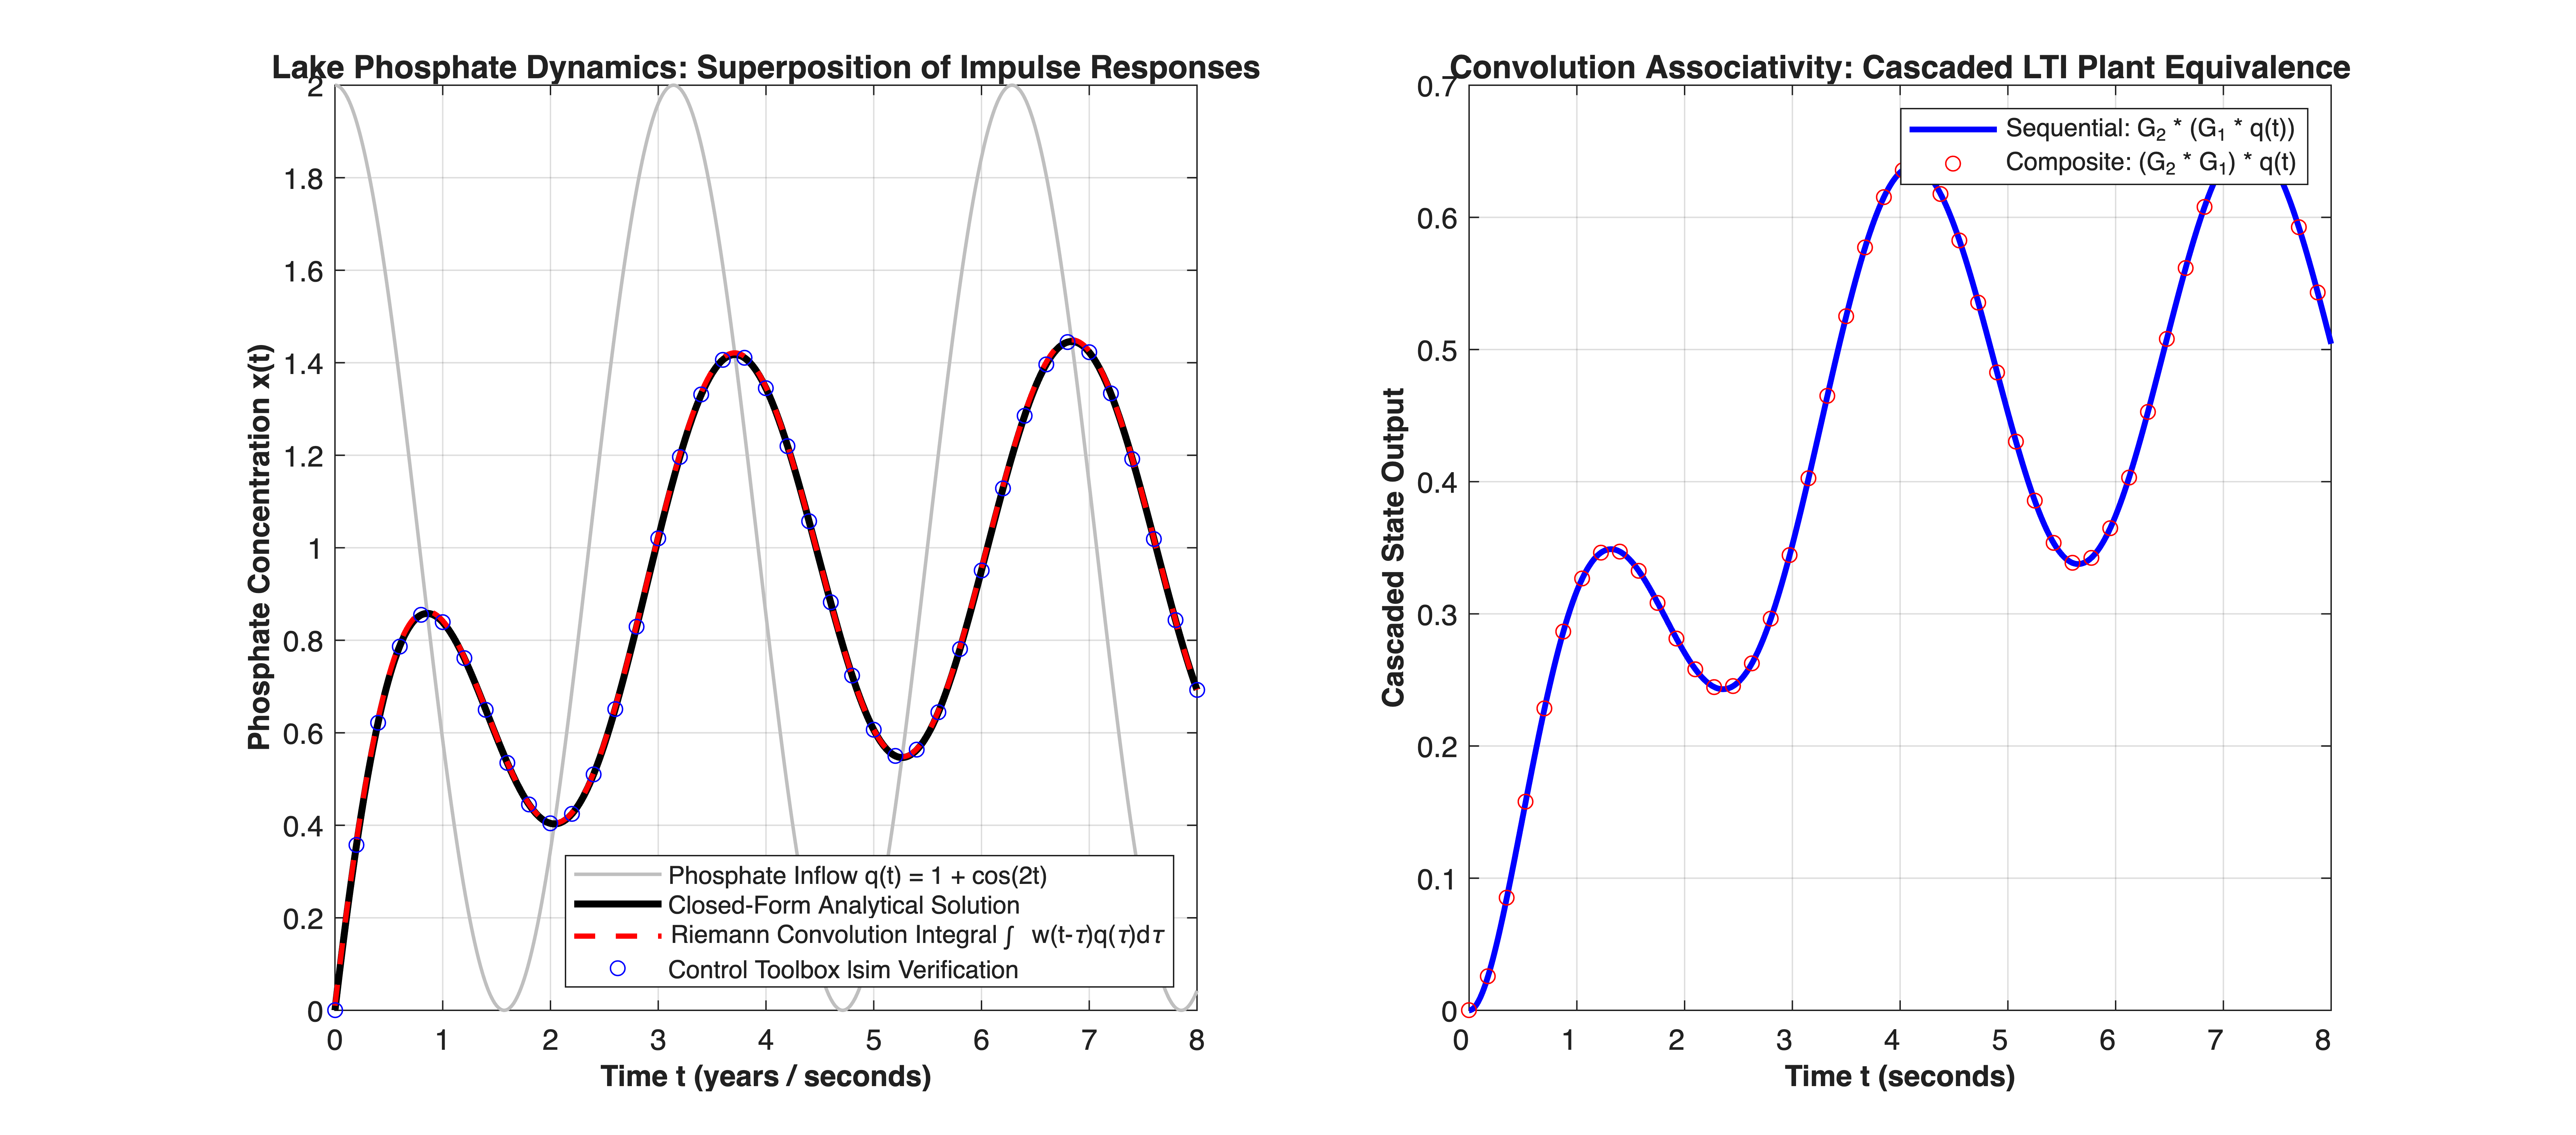

In [7]:


%% =========================================================================
%% Part 2: Visualization of Convolution Mechanics & Cascaded Systems
%% =========================================================================
figure('Color', [1 1 1], 'Position', [100, 100, 1180, 520]);


% Subplot 1: Response Verification (Convolution vs lsim vs Analytic)
subplot(1, 2, 1);
hold on; grid on; box on;


plot(t_vec, q_input, 'Color', [0.75 0.75 0.75], 'LineWidth', 1.2, ...
     'DisplayName', 'Phosphate Inflow q(t) = 1 + cos(2t)');
plot(t_vec, x_analytic, 'k-', 'LineWidth', 2.4, ...
     'DisplayName', 'Closed-Form Analytical Solution');
plot(t_vec, x_conv_numeric, 'r--', 'LineWidth', 1.8, ...
     'DisplayName', 'Riemann Convolution Integral \int w(t-\tau)q(\tau)d\tau');
plot(t_vec(1:40:end), x_lsim(1:40:end), 'bo', 'MarkerSize', 5, ...
     'DisplayName', 'Control Toolbox lsim Verification');


xlabel('Time t (years / seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Phosphate Concentration x(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Lake Phosphate Dynamics: Superposition of Impulse Responses', ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'southeast', 'FontSize', 8.5);
xlim([0, t_horizon]);


% Subplot 2: Cascaded System Associativity via Control Toolbox (Section [4])
% G1(s) = 1/(s + 1), G2(s) = 1/(s + 2)
G1 = tf(1, [1, 1]);
G2 = tf(1, [1, 2]);
G_cascade = series(G1, G2); % G_cascade(s) = G1(s) * G2(s)


% Path 1: Simulate step by step: u -> G1 -> y1 -> G2 -> y_path1
[y1_step, ~]     = lsim(G1, q_input, t_vec);
[y_path1, ~]     = lsim(G2, y1_step, t_vec);


% Path 2: Simulate composite system: u -> G_cascade -> y_path2
[y_path2, ~]     = lsim(G_cascade, q_input, t_vec);


subplot(1, 2, 2);
hold on; grid on; box on;


plot(t_vec, y_path1, 'b-', 'LineWidth', 2.0, ...
     'DisplayName', 'Sequential: G_2 * (G_1 * q(t))');
plot(t_vec(1:35:end), y_path2(1:35:end), 'ro', 'MarkerSize', 5, ...
     'DisplayName', 'Composite: (G_2 * G_1) * q(t)');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Cascaded State Output', 'FontSize', 10, 'FontWeight', 'bold');
title('Convolution Associativity: Cascaded LTI Plant Equivalence', ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5);
xlim([0, t_horizon]);